# 05 · Forecasting solar generation and demand with regression
**Level 3 · Predictive analytics (supervised)** &nbsp;|&nbsp; Course link: *Module 4 – forecasting with regression models*

Grid operators must know tomorrow's **solar output** (weather-driven supply) and **demand** (behaviour- and
temperature-driven). Supervised regression learns a mapping $f_\theta(x)\approx y$ from historical examples: inputs $x$
(weather, calendar) and targets $y$ (MW).

**Data:** Great Britain, hourly, 2016–2019: national solar and load (Open Power System Data) and weather averaged over
five cities (Open-Meteo).

> **Honest caveat:** we use *observed* weather as input. In operation you would use a *weather forecast*, which has its
> own errors, so real-world forecast errors are larger than the ones below.

## Training procedure
Choose parameters $\theta$ that minimise the **mean squared error** on the training data,
$$\text{MSE}=\frac1N\sum_{i=1}^{N}\left(y_i-\hat y_i\right)^2,\qquad \hat y_i=f_\theta(x_i),$$
and judge the model **only on data it has never seen**. For time series the test set must lie *after* the training
period (no shuffling), otherwise the model can "peek" at the future.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from energy_ai import gb_dataset, clean_load, style
style()

df = gb_dataset()
print(df.shape, "|", df.index.min(), "→", df.index.max())
print("yearly peak solar output [MW]:", df.solar_mw.resample("YE").max().round(0).to_dict())

(35052, 21) | 2016-01-01 00:00:00+00:00 → 2019-12-31 23:00:00+00:00
yearly peak solar output [MW]: {Timestamp('2016-12-31 00:00:00+0000', tz='UTC'): 7355.0, Timestamp('2017-12-31 00:00:00+0000', tz='UTC'): 8675.0, Timestamp('2018-12-31 00:00:00+0000', tz='UTC'): 9010.0, Timestamp('2019-12-31 00:00:00+0000', tz='UTC'): 9125.0}


Solar capacity in GB grew between 2016 and 2019 (yearly peak 7.4 → 9.1 GW). A model trained on 2016 would learn a
grid that no longer exists, so we **train on 2017–2018** and **test on 2019**.

In [2]:
train = df.loc["2017":"2018"]
test = df.loc["2019"]
CAP = train.solar_mw.max()          # capacity proxy, used to normalise errors (nRMSE)
print(f"train: 2017–2018 ({len(train)} hours) | test: 2019 ({len(test)} hours, never used for fitting — every error below "
      f"is measured on predictions for these hours)")

def scores(y, yhat, name, cap=None):
    r = {"model": name, "RMSE [MW]": np.sqrt(mean_squared_error(y, yhat)), "MAE [MW]": mean_absolute_error(y, yhat), "R²": r2_score(y, yhat)}
    if cap: r["nRMSE [% of capacity]"] = 100 * r["RMSE [MW]"] / cap
    else:   r["MAPE [%]"] = 100 * np.mean(np.abs((y - yhat) / y))
    return r

train: 2017–2018 (17508 hours) | test: 2019 (8760 hours, never used for fitting — every error below is measured on predictions for these hours)


## 1. Solar generation
### Baseline: persistence
Every forecast must beat a naive baseline. *Persistence* says: "same hour yesterday".

In [3]:
y_tr, y_te = train.solar_mw, test.solar_mw
persist = df.solar_mw.shift(24).loc[test.index]
rows = [scores(y_te, persist, "persistence (same hour yesterday)", CAP)]

### Simple linear regression: one input
Physics says PV output is roughly proportional to irradiance (GHI, W/m²): $\hat y = w_0 + w_1\cdot\text{GHI}$.

fitted: solar ≈ 41 + 10.31 × GHI   (MW per W/m²)


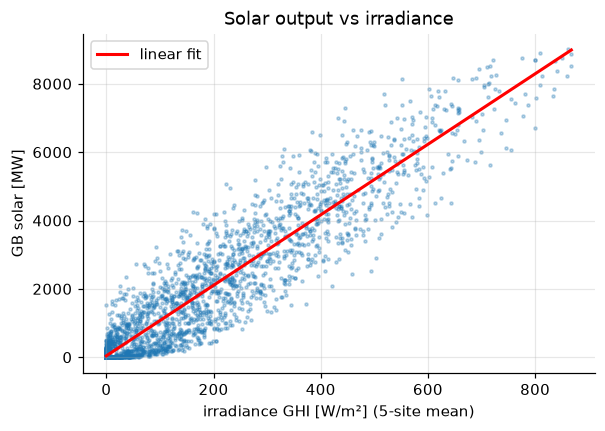

In [4]:
lr1 = LinearRegression().fit(train[["shortwave_radiation"]], y_tr)
pred1 = lr1.predict(test[["shortwave_radiation"]]).clip(0)
rows.append(scores(y_te, pred1, "linear: GHI only", CAP))
print(f"fitted: solar ≈ {lr1.intercept_:.0f} + {lr1.coef_[0]:.2f} × GHI   (MW per W/m²)")

fig, ax = plt.subplots(figsize=(6, 4))
s = train.sample(4000, random_state=0)
ax.scatter(s.shortwave_radiation, s.solar_mw, s=4, alpha=0.3)
g = np.linspace(0, s.shortwave_radiation.max(), 50)
ax.plot(g, lr1.predict(pd.DataFrame({"shortwave_radiation": g})), "r", lw=2, label="linear fit")
ax.set(xlabel="irradiance GHI [W/m²] (5-site mean)", ylabel="GB solar [MW]", title="Solar output vs irradiance"); ax.legend(); plt.show()

### Multiple linear regression: more physics in the features
The cloud of points is wide because the same irradiance gives more power around noon (better panel angle) and less
when panels are hot. We add solar elevation, direct/diffuse split, temperature, cloud cover and season, plus the
interaction GHI × sin(elevation):
$$\hat y = w_0 + \sum_j w_j x_j$$

In [5]:
def solar_features(d):
    X = d[["shortwave_radiation", "direct_radiation", "diffuse_radiation", "temperature_2m", "cloud_cover",
           "solar_elevation", "doy_sin", "doy_cos"]].copy()
    X["ghi_x_sin_elev"] = d.shortwave_radiation * np.sin(np.radians(d.solar_elevation.clip(lower=0)))
    X["ghi_x_temp"] = d.shortwave_radiation * d.temperature_2m
    return X

Xs_tr, Xs_te = solar_features(train), solar_features(test)
lr2 = LinearRegression().fit(Xs_tr, y_tr)
pred2 = lr2.predict(Xs_te).clip(0)
rows.append(scores(y_te, pred2, "multiple linear (10 features)", CAP))
display(pd.DataFrame(rows).set_index("model").round(3))

,RMSE [MW],MAE [MW],R²,nRMSE [% of capacity]
model,,,,
persistence (same hour yesterday),875.758,415.149,0.794,9.720
linear: GHI only,630.184,382.368,0.893,6.994
multiple linear (10 features),556.900,351.728,0.917,6.181


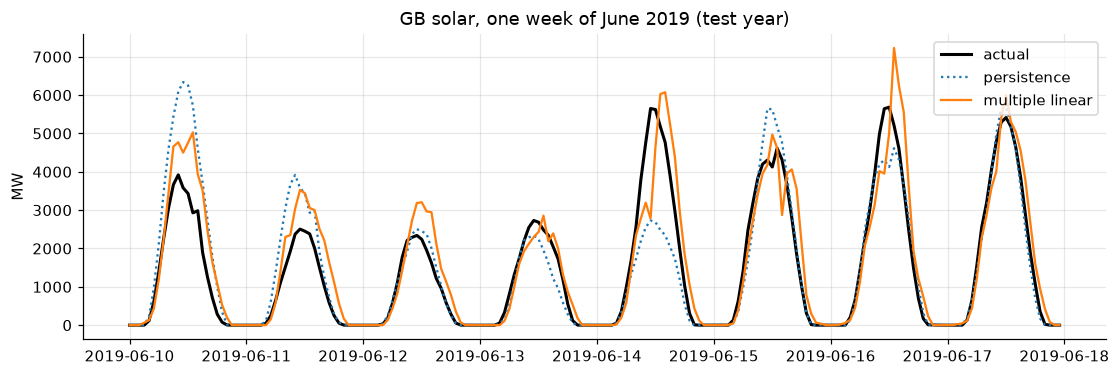

In [6]:
week = slice("2019-06-10", "2019-06-17")
fig, ax = plt.subplots(figsize=(12, 3.6))
ax.plot(y_te.loc[week], "k", lw=2, label="actual")
ax.plot(pd.Series(persist, index=test.index).loc[week], ls=":", label="persistence")
ax.plot(pd.Series(pred2, index=test.index).loc[week], label="multiple linear")
ax.set(title="GB solar, one week of June 2019 (test year)", ylabel="MW"); ax.legend(); plt.show()

Persistence fails on days whose weather differs from yesterday; the regression follows the weather.

## 2. Overfitting in one picture: polynomial degree
More flexible models fit the training data better, but past a point they **memorise noise** and generalise worse.
We fit polynomials of increasing degree to GHI on a small training sample.

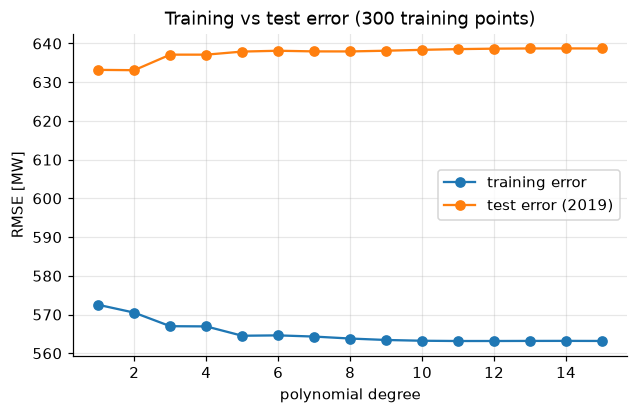

best test degree: 2


In [7]:
small = train.sample(300, random_state=1)
degs = range(1, 16)
tr_err, te_err = [], []
for dgr in degs:
    m = make_pipeline(PolynomialFeatures(dgr), Ridge(alpha=1e-6)).fit(small[["shortwave_radiation"]] / 1000, small.solar_mw)
    tr_err.append(np.sqrt(mean_squared_error(small.solar_mw, m.predict(small[["shortwave_radiation"]] / 1000))))
    te_err.append(np.sqrt(mean_squared_error(y_te, m.predict(test[["shortwave_radiation"]] / 1000).clip(0, 3 * CAP))))
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(list(degs), tr_err, "o-", label="training error"); ax.plot(list(degs), te_err, "o-", label="test error (2019)")
ax.set(xlabel="polynomial degree", ylabel="RMSE [MW]", title="Training vs test error (300 training points)"); ax.legend(); plt.show()
print("best test degree:", list(degs)[int(np.argmin(te_err))])

Training error keeps falling; test error falls, then rises. The gap is **overfitting**, and it is why we always keep
a test set the model never sees.

## 3. Electricity demand
### First: clean the data
Real data is dirty. The GB demand series contains reporting errors: hours where demand "drops" to 2 GW (instead of
~45 GW) or jumps by 30 GW within one hour. Physically impossible for a national grid, but they would dominate the
error metrics. `clean_load` flags values that are far from the same hour in neighbouring weeks (real demand never falls
below 60 % of that, even at Christmas) and isolated one-hour spikes, then fills them in.

flagged 95 of 35052 hours (0.27%); holiday hours kept untouched


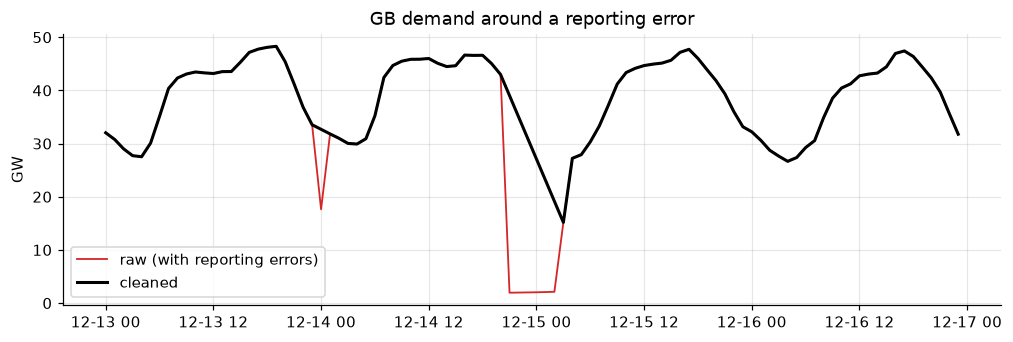

In [8]:
raw = df.load_mw.copy()
clean, flagged = clean_load(raw)
print(f"flagged {int(flagged.sum())} of {len(raw)} hours ({flagged.mean():.2%}); holiday hours kept untouched")
w = slice("2018-12-13", "2018-12-16")
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(raw.loc[w] / 1000, color="tab:red", lw=1.2, label="raw (with reporting errors)")
ax.plot(clean.loc[w] / 1000, "k", lw=2, label="cleaned")
ax.set(title="GB demand around a reporting error", ylabel="GW"); ax.legend(); plt.show()
df["load_mw"] = clean
train, test = df.loc["2017":"2018"], df.loc["2019"]

### A linear demand model
Demand follows human routines (hour of the week, holidays) and temperature (heating). A linear model with one
indicator ("dummy") per hour of the week plus temperature terms captures most of it:
$$\hat y = \sum_{h=0}^{167} \beta_h\,\mathbb{1}[\text{hour-of-week}=h] + \gamma_1\,\text{HDD} + \gamma_2\,\text{CDD} + \sum_m \delta_m\,\mathbb{1}[\text{month}=m]$$
with heating degree $\text{HDD}=\max(15.5-T,0)$ and cooling degree $\text{CDD}=\max(T-18,0)$.

,RMSE [MW],MAE [MW],R²,MAPE [%]
model,,,,
seasonal naive (same hour last week),2688.245,1977.651,0.866,6.090
linear: hour-of-week + temperature + month,2237.561,1684.251,0.907,5.261


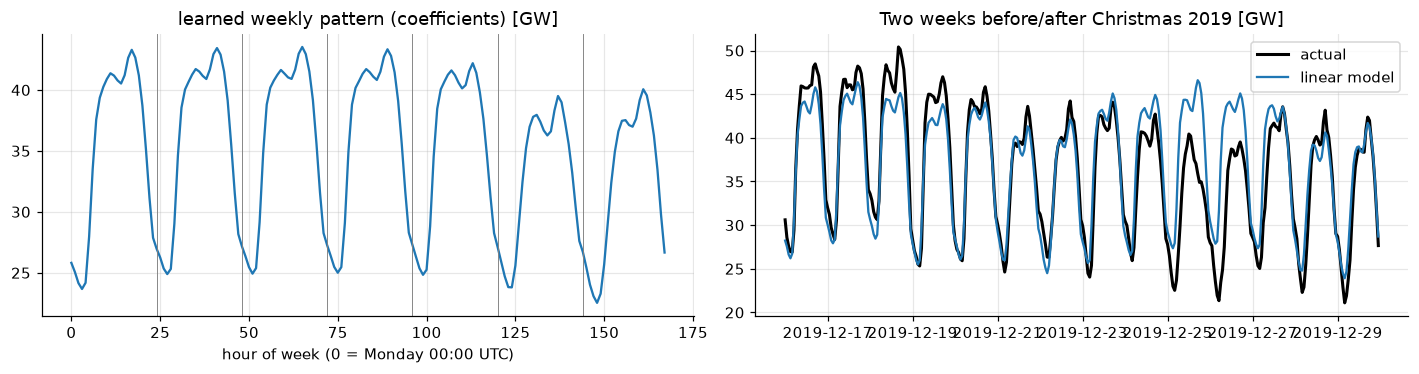

In [9]:
def load_features(d):
    how = pd.get_dummies(d.dayofweek * 24 + d.hour, prefix="how").astype(float)
    mon = pd.get_dummies(d.month, prefix="m", drop_first=True).astype(float)
    X = pd.concat([how, mon], axis=1)
    X["HDD"] = (15.5 - d.temperature_2m).clip(lower=0)
    X["CDD"] = (d.temperature_2m - 18).clip(lower=0)
    X["HDD_x_dark"] = X.HDD * (d.solar_elevation < 0)
    return X

XL_tr, XL_te = load_features(train), load_features(test).reindex(columns=load_features(train).columns, fill_value=0)
lrL = LinearRegression(fit_intercept=False).fit(XL_tr, train.load_mw)
predL = lrL.predict(XL_te)
naive_week = df.load_mw.shift(168).loc[test.index]
load_rows = [scores(test.load_mw, naive_week, "seasonal naive (same hour last week)"),
             scores(test.load_mw, predL, "linear: hour-of-week + temperature + month")]
display(pd.DataFrame(load_rows).set_index("model").round(3))

hw = pd.Series(lrL.coef_[:168], index=range(168))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
ax[0].plot(hw.values / 1000); ax[0].set(title="learned weekly pattern (coefficients) [GW]", xlabel="hour of week (0 = Monday 00:00 UTC)")
for k in range(1, 7): ax[0].axvline(24 * k, color="grey", lw=0.6)
w2 = slice("2019-12-16", "2019-12-29")
ax[1].plot(test.load_mw.loc[w2] / 1000, "k", lw=2, label="actual"); ax[1].plot(pd.Series(predL, index=test.index).loc[w2] / 1000, label="linear model")
ax[1].set(title="Two weeks before/after Christmas 2019 [GW]"); ax[1].legend()
plt.tight_layout(); plt.show()

The model has learned the daily shape and the weekend dip, but it **fails around Christmas**: holidays are not in its
features. Let us add domain knowledge: official bank holidays and the Christmas period.

,RMSE [MW],MAE [MW],R²,MAPE [%]
model,,,,
seasonal naive (same hour last week),2688.245,1977.651,0.866,6.090
linear: hour-of-week + temperature + month,2237.561,1684.251,0.907,5.261
linear + bank holidays + Christmas period,2072.350,1609.896,0.920,5.043


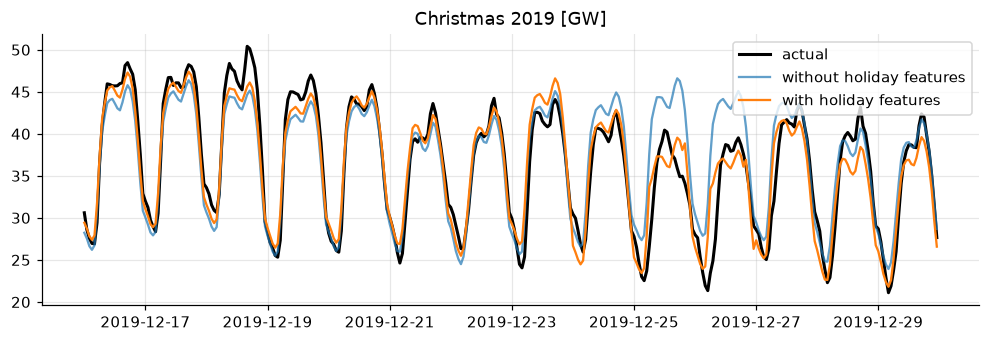

In [10]:
import holidays
hol = holidays.UK(subdiv="ENG", years=range(2016, 2020))

def load_features_v2(d):
    X = load_features(d)
    X["bank_holiday"] = np.array([dt in hol for dt in d.index.date], dtype=float)
    X["xmas_period"] = (((d.month == 12) & (d.index.day >= 24)) | ((d.month == 1) & (d.index.day <= 2))).astype(float)
    X["bank_holiday_x_day"] = X.bank_holiday * d.hour.between(7, 19)
    return X

X2_tr = load_features_v2(train); X2_te = load_features_v2(test).reindex(columns=X2_tr.columns, fill_value=0)
lrL2 = LinearRegression(fit_intercept=False).fit(X2_tr, train.load_mw)
predL2 = lrL2.predict(X2_te)
load_rows.append(scores(test.load_mw, predL2, "linear + bank holidays + Christmas period"))
display(pd.DataFrame(load_rows).set_index("model").round(3))
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(test.load_mw.loc[w2] / 1000, "k", lw=2, label="actual")
ax.plot(pd.Series(predL, index=test.index).loc[w2] / 1000, alpha=0.7, label="without holiday features")
ax.plot(pd.Series(predL2, index=test.index).loc[w2] / 1000, label="with holiday features")
ax.set(title="Christmas 2019 [GW]"); ax.legend(); plt.show()

Two simple, well-chosen features fix most of the Christmas error. **Feature engineering with domain knowledge is often
worth more than a fancier algorithm.** The course mentions the same idea for major events (sports finals, TV
breaks): if the model does not know about an event, it cannot predict it.

## Key takeaways
* Always start with a naive baseline (persistence, seasonal naive) and judge on a later, unseen period.
* Linear regression is fast and interpretable; its quality depends on the **features** you give it.
* Normalise errors (nRMSE by capacity, MAPE by demand) to compare forecasts across systems.
* Clean the data first: a handful of reporting errors doubled the measured error of the demand forecasts.
* Watch for changing systems (solar capacity growth) and rare events (holidays) that the training data does not cover.

**Next (notebook 06):** non-linear models (trees, ensembles, neural networks) and the UK National Grid style ensemble.